In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset shape (samples, features):", X.shape)
print("Target classes:", data.target_names)
print(f"Class distribution: {np.bincount(y)} (0 = Malignant, 1 = Benign)")

Dataset shape (samples, features): (569, 30)
Target classes: ['malignant' 'benign']
Class distribution: [212 357] (0 = Malignant, 1 = Benign)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples:  {X_test.shape[0]}")

Training samples: 455
Testing samples:  114


In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Features scaled successfully (mean ~ 0, standard deviation ~ 1).")

Features scaled successfully (mean ~ 0, standard deviation ~ 1).


In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

print("Model training complete.")

Model training complete.


Confusion Matrix:
 [[41  1]
 [ 1 71]]


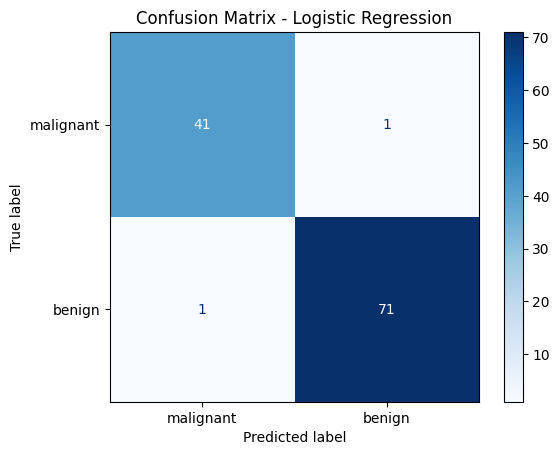

In [ ]:
y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=data.target_names
)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.grid(False)
plt.show()

In [ ]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("--- Performance Metrics ---")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred, target_names=data.target_names))

--- Performance Metrics ---
Precision : 0.9861
Recall    : 0.9861
F1-Score  : 0.9861

--- Detailed Classification Report ---
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



ROC-AUC Score: 0.9954


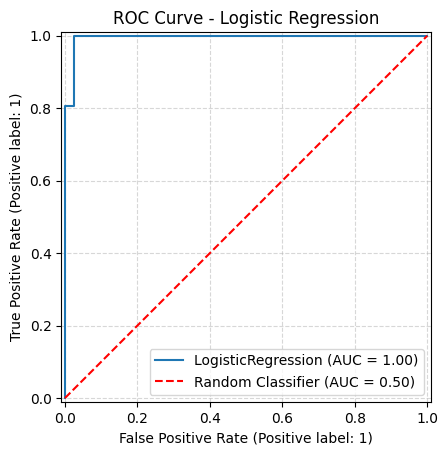

In [ ]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score

# 1. Obtain probability scores for the positive class (Benign)
y_prob = model.predict_proba(X_test)[:, 1]

# 2. Compute Area Under the Curve (AUC)
auc_score = roc_auc_score(y_test, y_prob)
print(f"ROC-AUC Score: {auc_score:.4f}")

# 3. Plot ROC Curve
RocCurveDisplay.from_estimator(model, X_test, y_test)
plt.title("ROC Curve - Logistic Regression")
plt.plot([0, 1], [0, 1], "r--", label="Random Classifier (AUC = 0.50)")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()